In [4]:
import matplotlib.pyplot as plt
import numpy as np
import cv2
import skimage as ski
import scipy as sp
import imageio.v3 as iio
from dataclasses import dataclass
import math
from scipy import ndimage
from skimage.segmentation import watershed


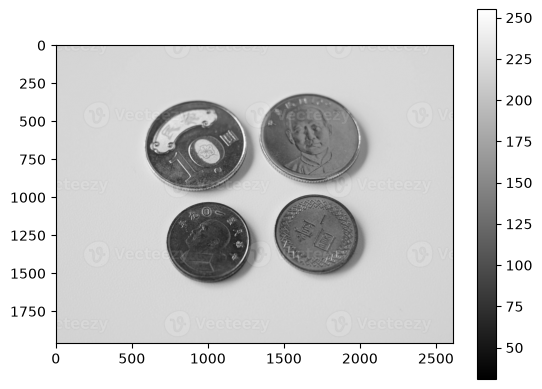

cercle détecté : centre=(1770, 513), taille=290
cercle détecté : centre=(981, 682), taille=224
cercle détecté : centre=(752, 695), taille=310
cercle détecté : centre=(1878, 622), taille=270
cercle détecté : centre=(1792, 578), taille=204
cercle détecté : centre=(1805, 418), taille=154
cercle détecté : centre=(1848, 479), taille=200
cercle détecté : centre=(752, 548), taille=230
cercle détecté : centre=(1142, 708), taille=194
cercle détecté : centre=(752, 795), taille=188
cercle détecté : centre=(708, 622), taille=148
cercle détecté : centre=(1051, 669), taille=260
cercle détecté : centre=(1168, 1328), taille=190
13 cercles détectés


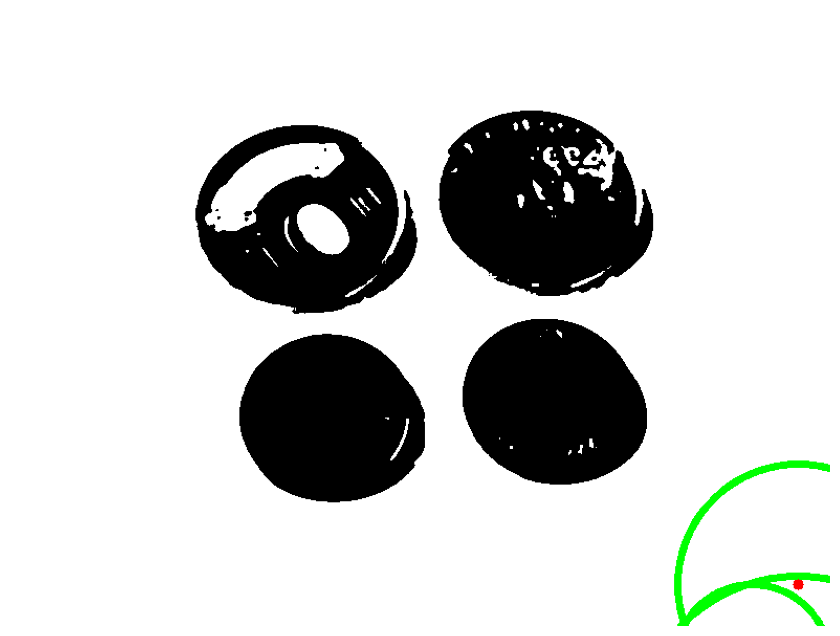

In [2]:
chemin = './data/1-yuan-and-10-yuan-taiwan-coin-close-up-isolated-on-a-white-background-photo.jpg'

taille = plt.imread(chemin)
a_gris = cv2.cvtColor(taille, cv2.COLOR_RGB2GRAY)
plt.imshow(a_gris, cmap='gray')
plt.colorbar()
plt.show()

piece = cv2.imread(chemin, cv2.IMREAD_GRAYSCALE) # on force l'image a rester en niveau de gris (car c'est plus simple pour detecter les cercles)
#piece = piece[:270, 80:420] # on recadre jsp si c'est vrm utile
echelle = 0.3
piece_reduite = cv2.resize(piece, None, fx=echelle, fy=echelle, interpolation=cv2.INTER_AREA) # pour reduire la quelité pour que ça aille plus vite
piece_floue = cv2.medianBlur(piece_reduite, 5) # pour ne pas etre perturbé par certain détail (c'est juste pour la detection des cercles)
seuil, img_binaire = cv2.threshold(piece_floue, 150, 255, cv2.THRESH_BINARY)
image_resultat = cv2.cvtColor(img_binaire, cv2.COLOR_GRAY2RGB) # permet a la fin de pouvoir rajouter des couleurs sur l'image (car plus tot j'ai forcer l'image a rester en niveau de gris)

cercles = cv2.HoughCircles(
    img_binaire, # l'image sur la quel on cherche les cercles
    cv2.HOUGH_GRADIENT, # la methode
    dp=1.3, # a quel point ça dois etre un cercle parfait (1 c'est parfait, 1.2 ça peut être légeremnt oval)
    minDist=20, # la distance minimale entre 2 cercle, pour eviter de detecter 2 fois la mme piece
    param1=50, # plus c'est haut plus le contours doit etre net pour etre detecte
    param2=20, # le taux de fiabilité (plus c'est haut plus il a tendance a detecter des cercle)
    minRadius=20, # les limite de tailles des rayons des cercle
    maxRadius=50,
)

if piece is None:
    raise FileNotFoundError(f'Image introuvable : {chemin}')

if cercles is None:
    print('Aucun cercle détecté. Essaie de diminuer param2 ou ajuste minRadius/maxRadius.')
else:
    cercles = np.round(cercles[0] / echelle).astype(int)
    for x, y, rayon in cercles:
        cv2.circle(image_resultat, (x, y), rayon, (0, 255, 0), 5)
        cv2.circle(image_resultat, (x, y), 5, (255, 0, 0), -1)
        print(f'cercle détecté : centre=({x}, {y}), taille={rayon*2}')
    print(f'{len(cercles)} cercles détectés')

plt.figure(figsize=(14, 8))
plt.imshow(image_resultat)
plt.axis('off')
plt.show()

In [3]:
import imageio.v3 as iio
import matplotlib.pyplot as plt
import skimage as ski


coins = "./data/43fef775db14373494f2246ff3754a16_t.jpg"
edges = ski.feature.canny(coins / 255.)
fill_coins = sp.ndimage.binary_fill_holes(edges)

TypeError: unsupported operand type(s) for /: 'str' and 'float'

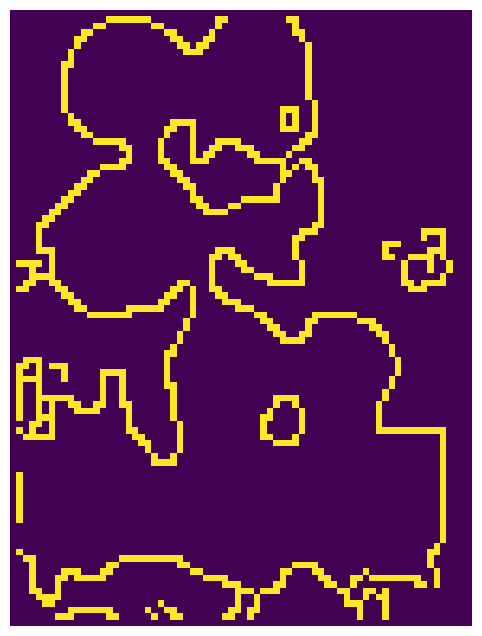

In [ ]:
image = './data/images.jpg'
img = cv2.imread(image, cv2.IMREAD_GRAYSCALE)
echelle = 0.15
piece_reduite = cv2.resize(img, None, fx=echelle, fy=echelle, interpolation=cv2.INTER_AREA)
piece_floue = cv2.medianBlur(piece_reduite, 5)
seuil, img_binaire = cv2.threshold(piece_floue, 127, 255, cv2.THRESH_BINARY)
edges = ski.feature.canny(img_binaire / 255.)
fill_coins = sp.ndimage.binary_fill_holes(edges)

plt.figure(figsize=(14, 8))
plt.imshow(edges)
plt.axis('off')
plt.show()

Image : data/IMG_5677.jpg
Pièces détectées : 5
  Pièce 1 : diamètre environ 192 px, valeur estimée = 50
  Pièce 2 : diamètre environ 180 px, valeur estimée = 50
  Pièce 3 : diamètre environ 148 px, valeur estimée = 5
  Pièce 4 : diamètre environ 146 px, valeur estimée = 5
  Pièce 5 : diamètre environ 130 px, valeur estimée = 1
Total estimé : 111
Vérifiez les étiquettes sur l'image : le classement des tailles et les tailles manquantes sont des estimations.


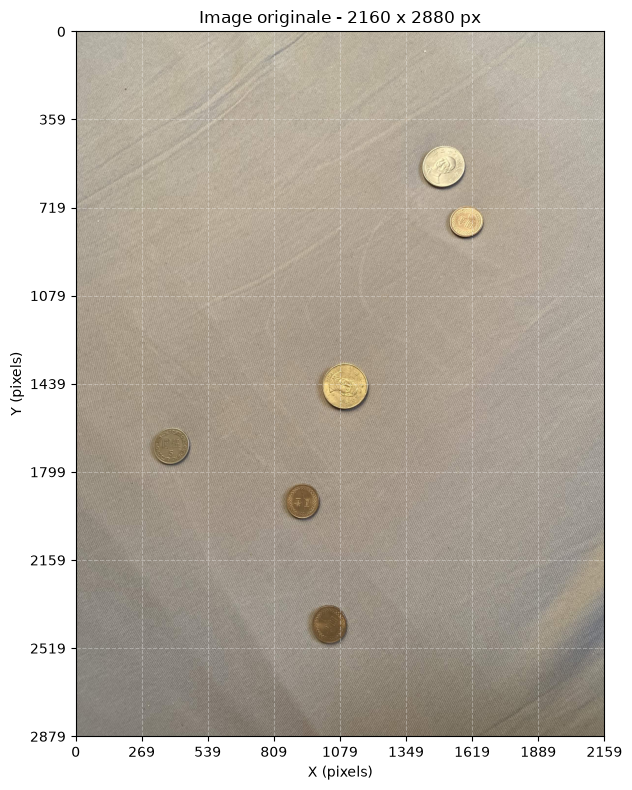

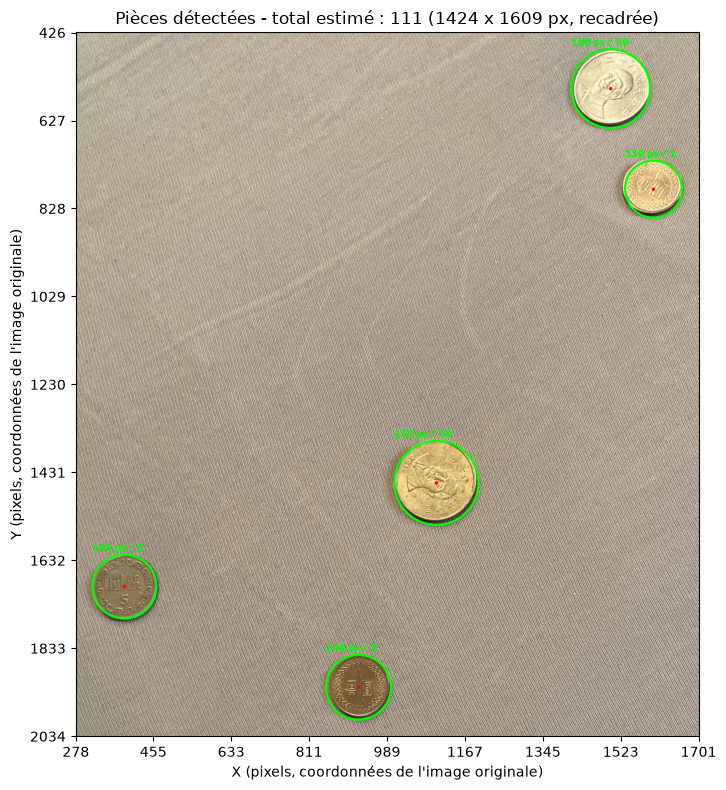

In [33]:
CHEMIN_IMAGE = "data/IMG_5677.jpg"

TAILLES_VALEURS = [50, 10, 5, 1]
TAILLE_MAX_IMAGE = 1400
TOLERANCE_REGROUPEMENT = 0.08
RAPPORT_TAILLE_MANQUANTE = 1.25


@dataclass
class Piece:
    x: int
    y: int
    diametre_px: float
    lab_b: float
    valeur: int | None = None


def score_contour_circulaire(
    gradients_x: np.ndarray, gradients_y: np.ndarray,
    x: float, y: float, rayon: float,
) -> float:
    """Mesure la continuit? du bord d'un cercle dans l'image r?duite."""
    angles = np.linspace(0, 2 * math.pi, 72, endpoint=False)
    score = np.zeros(angles.shape, dtype=np.float32)

    for decalage in (-2, 0, 2):
        xs = np.rint(x + (rayon + decalage) * np.cos(angles)).astype(int)
        ys = np.rint(y + (rayon + decalage) * np.sin(angles)).astype(int)
        valides = (xs >= 1) & (xs < gradients_x.shape[1] - 1) & (ys >= 1) & (ys < gradients_x.shape[0] - 1)
        xs = np.clip(xs, 1, gradients_x.shape[1] - 2)
        ys = np.clip(ys, 1, gradients_x.shape[0] - 2)
        gradient_radial = np.abs(
            gradients_x[ys, xs] * np.cos(angles)
            + gradients_y[ys, xs] * np.sin(angles)
        )
        score = np.maximum(score, np.where(valides, gradient_radial, 0))

    return float(np.mean(score))


def mesurer_couleur_chaude(image: np.ndarray, x: int, y: int, diametre: float) -> float:
    """Mesure le jaune/doré au centre de la pièce, sans inclure son arrière-plan."""
    rayon = diametre / 2
    marge = max(1, round(rayon * 0.7))
    x_min, x_max = max(0, x - marge), min(image.shape[1], x + marge + 1)
    y_min, y_max = max(0, y - marge), min(image.shape[0], y + marge + 1)
    zone = image[y_min:y_max, x_min:x_max]

    lignes, colonnes = np.ogrid[y_min:y_max, x_min:x_max]
    distance = np.sqrt((colonnes - x) ** 2 + (lignes - y) ** 2)
    masque = (distance >= rayon * 0.2) & (distance <= rayon * 0.68)
    lab = cv2.cvtColor(zone, cv2.COLOR_BGR2LAB)
    return float(np.median(lab[:, :, 2][masque]))


def detecter_pieces(image: np.ndarray) -> list[Piece]:
    """Repère les cercles et renvoie leur centre et leur diamètre en pixels."""
    hauteur, largeur = image.shape[:2]
    facteur = min(1.0, TAILLE_MAX_IMAGE / max(hauteur, largeur))

    if facteur < 1:
        image_reduite = cv2.resize(
            image, None, fx=facteur, fy=facteur, interpolation=cv2.INTER_AREA
        )
    else:
        image_reduite = image

    gris = cv2.cvtColor(image_reduite, cv2.COLOR_BGR2GRAY)
    flou = cv2.medianBlur(gris, 5)
    cote_court = min(flou.shape)

    bordure = np.concatenate((flou[0, :], flou[-1, :], flou[:, 0], flou[:, -1]))
    if float(np.median(bordure)) < 128:
        _, masque = cv2.threshold(
            gris, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
        )
        noyau = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
        masque = cv2.morphologyEx(masque, cv2.MORPH_CLOSE, noyau)
        masque = cv2.morphologyEx(masque, cv2.MORPH_OPEN, noyau)

        rayon_min = max(6, int(cote_court * 0.02))
        rayon_max = max(12, int(cote_court * 0.12))
        aire_min = math.pi * rayon_min**2 * 1.25
        aire_max = math.pi * rayon_max**2 * 1.6
        distance = cv2.distanceTransform(masque, cv2.DIST_L2, 5)
        taille_fenetre = max(15, int(cote_court * 0.04))
        maximum_distance = max(10, cote_court * 0.025)
        maxima = (
            (distance == ndimage.maximum_filter(distance, size=taille_fenetre))
            & (distance > maximum_distance)
            & (masque > 0)
        )
        etiquettes_maxima, nombre_maxima = ndimage.label(maxima)
        candidats: list[tuple[float, int, int]] = []

        for indice in range(1, nombre_maxima + 1):
            ys, xs = np.where(etiquettes_maxima == indice)
            if len(xs):
                position = int(np.argmax(distance[ys, xs]))
                candidats.append(
                    (
                        float(distance[ys[position], xs[position]]),
                        int(xs[position]),
                        int(ys[position]),
                    )
                )

        candidats.sort(reverse=True)
        distance_minimale = max(18, int(cote_court * 0.045))
        centres_pieces: list[tuple[float, int, int]] = []
        for candidat in candidats:
            _, x, y = candidat
            trop_proche = any(
                math.hypot(x - autre_x, y - autre_y) < distance_minimale
                for _, autre_x, autre_y in centres_pieces
            )
            if not trop_proche:
                centres_pieces.append(candidat)

        marqueurs = np.zeros(masque.shape, dtype=np.int32)
        for indice, (_, x, y) in enumerate(centres_pieces, start=1):
            marqueurs[y, x] = indice

        regions = watershed(-distance, marqueurs, mask=masque > 0)
        pieces_segmentees: list[Piece] = []

        for indice, (_, x, y) in enumerate(centres_pieces, start=1):
            aire = int(np.count_nonzero(regions == indice))
            if aire_min <= aire <= aire_max:
                pieces_segmentees.append(
                    Piece(
                        x=round(x / facteur),
                        y=round(y / facteur),
                        diametre_px=2 * math.sqrt(aire / math.pi) / facteur,
                        lab_b=0,
                    )
                )

        if pieces_segmentees and len(pieces_segmentees) <= 12:
            for piece in pieces_segmentees:
                piece.lab_b = mesurer_couleur_chaude(
                    image, piece.x, piece.y, piece.diametre_px
                )
            return pieces_segmentees

    if cote_court < 600:
        seuil_hough = 38
        rayon_min = max(6, int(cote_court * 0.015))
        rayon_max = max(12, int(cote_court * 0.12))
    else:
        seuil_hough = 45
        rayon_min = max(6, int(cote_court * 0.02))
        rayon_max = max(12, int(cote_court * 0.10))

    cercles = cv2.HoughCircles(
        flou,
        cv2.HOUGH_GRADIENT,
        dp=1.2,
        minDist=max(15, int(cote_court * 0.04)),
        param1=140,
        param2=seuil_hough,
        minRadius=rayon_min,
        maxRadius=rayon_max,
    )

    if cercles is None:
        return []

    pieces: list[Piece] = []
    for x, y, rayon in cercles[0]:
        piece = Piece(
            x=round(x / facteur),
            y=round(y / facteur),
            diametre_px=2 * rayon / facteur,
            lab_b=0,
        )

        # Hough peut proposer plusieurs cercles presque concentriques pour une pièce.
        doublon = any(
            math.hypot(piece.x - autre.x, piece.y - autre.y)
            < min(piece.diametre_px, autre.diametre_px) * 0.35
            and abs(piece.diametre_px - autre.diametre_px)
            / max(piece.diametre_px, autre.diametre_px)
            < 0.25
            for autre in pieces
        )
        if not doublon:
            pieces.append(piece)

    for piece in pieces:
        piece.lab_b = mesurer_couleur_chaude(
            image, piece.x, piece.y, piece.diametre_px
        )

    if len(pieces) > 12:
        seuil_contour = (
            105 if len(pieces) > 250
            else 90 if len(pieces) > 150
            else 78 if len(pieces) > 50
            else 88
        )
        gradients_x = cv2.Sobel(flou, cv2.CV_32F, 1, 0, ksize=3)
        gradients_y = cv2.Sobel(flou, cv2.CV_32F, 0, 1, ksize=3)
        pieces = [
            piece for piece in pieces
            if score_contour_circulaire(
                gradients_x, gradients_y, piece.x * facteur, piece.y * facteur,
                piece.diametre_px * facteur / 2,
            ) >= seuil_contour
        ]

    pieces = sorted(pieces, key=lambda piece: piece.diametre_px, reverse=True)
    pieces_filtrees: list[Piece] = []
    for piece in pieces:
        cercle_interieur = any(
            autre.diametre_px > piece.diametre_px * 1.25
            and math.hypot(piece.x - autre.x, piece.y - autre.y)
            < piece.diametre_px * 0.4
            for autre in pieces_filtrees
        )
        if not cercle_interieur:
            pieces_filtrees.append(piece)

    return pieces_filtrees


def regrouper_par_taille(pieces: list[Piece]) -> list[list[Piece]]:
    """Rassemble les diamètres proches en groupes, du plus petit au plus grand."""
    groupes: list[list[Piece]] = []

    for piece in sorted(pieces, key=lambda p: p.diametre_px):
        if not groupes:
            groupes.append([piece])
            continue

        diametre_median = float(
            np.median([membre.diametre_px for membre in groupes[-1]])
        )
        ecart_relatif = abs(piece.diametre_px - diametre_median) / diametre_median
        if ecart_relatif <= TOLERANCE_REGROUPEMENT:
            groupes[-1].append(piece)
        else:
            groupes.append([piece])

    return groupes


def attribuer_valeurs(groupes: list[list[Piece]]) -> None:
    """Utilise la couleur pour séparer les 50 des 10, puis compare les diamètres."""
    pieces = [piece for groupe in groupes for piece in groupe]
    plus_grand_diametre = max(piece.diametre_px for piece in pieces)
    grandes_pieces = [
        piece
        for piece in pieces
        if piece.diametre_px >= plus_grand_diametre * 0.9
    ]

    pieces_de_50: list[Piece] = []
    if len(grandes_pieces) >= 3:
        couleurs = sorted(piece.lab_b for piece in grandes_pieces)
        ecarts = [
            (couleurs[i + 1] - couleurs[i], i)
            for i in range(len(couleurs) - 1)
        ]
        ecart_max, position_ecart = max(ecarts)

        # Sur ces pièces, une surface dorée distingue les 50 des 10 argentées.
        if ecart_max >= 12:
            seuil_couleur = (
                couleurs[position_ecart] + couleurs[position_ecart + 1]
            ) / 2
            pieces_de_50 = [
                piece
                for piece in grandes_pieces
                if piece.lab_b > seuil_couleur
            ]

    for piece in pieces_de_50:
        piece.valeur = 50

    pieces_a_classer = [piece for piece in pieces if piece not in pieces_de_50]
    groupes_a_classer = regrouper_par_taille(pieces_a_classer)
    groupes_grands_vers_petits = list(reversed(groupes_a_classer))

    # Si les 50 ont été séparées par couleur, les autres tailles commencent à 10.
    indice_valeur = 1 if pieces_de_50 else 0

    for position, groupe in enumerate(groupes_grands_vers_petits):
        if position:
            diametre_precedent = float(
                np.median(
                    [piece.diametre_px for piece in groupes_grands_vers_petits[position - 1]]
                )
            )
            diametre_actuel = float(
                np.median([piece.diametre_px for piece in groupe])
            )
            rapport = diametre_precedent / diametre_actuel

            # Un grand écart peut signaler une ou plusieurs tailles absentes.
            if rapport > RAPPORT_TAILLE_MANQUANTE:
                pas = 2 + int(
                    math.log(
                        rapport / RAPPORT_TAILLE_MANQUANTE,
                        RAPPORT_TAILLE_MANQUANTE,
                    )
                )
            else:
                pas = 1
            indice_valeur += pas

            # Avec quatre groupes ou moins, la plus petite classe ne peut pas
            # être plus petite que la quatrième valeur prévue.
            if len(groupes) <= len(TAILLES_VALEURS):
                indice_valeur = min(indice_valeur, len(TAILLES_VALEURS) - 1)

        valeur = (
            TAILLES_VALEURS[indice_valeur]
            if indice_valeur < len(TAILLES_VALEURS)
            else None
        )
        for piece in groupe:
            piece.valeur = valeur



def main() -> None:
    image = cv2.imread(str(CHEMIN_IMAGE))
    if image is None:
        raise FileNotFoundError(f"Image introuvable ou illisible : {CHEMIN_IMAGE}")

    hauteur, largeur = image.shape[:2]
    plt.figure(figsize=(14, 8))
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(f"Image originale - {largeur} x {hauteur} px")
    plt.xlabel("X (pixels)")
    plt.ylabel("Y (pixels)")
    plt.xticks(np.linspace(0, largeur - 1, num=min(9, largeur), dtype=int))
    plt.yticks(np.linspace(0, hauteur - 1, num=min(9, hauteur), dtype=int))
    plt.grid(color="white", alpha=0.3, linestyle="--")
    plt.tight_layout()

    pieces = detecter_pieces(image)
    if not pieces:
        print("Aucune pièce détectée. Vérifiez l'image et les paramètres de détection.")
        plt.show()
        return

    groupes = regrouper_par_taille(pieces)
    attribuer_valeurs(groupes)

    total = sum(piece.valeur or 0 for piece in pieces)
    inconnues = sum(piece.valeur is None for piece in pieces)

    print(f"Image : {CHEMIN_IMAGE}")
    print(f"Pièces détectées : {len(pieces)}")
    for numero, piece in enumerate(pieces, start=1):
        valeur = "indéterminée" if piece.valeur is None else str(piece.valeur)
        print(
            f"  Pièce {numero} : diamètre environ {piece.diametre_px:.0f} px, "
            f"valeur estimée = {valeur}"
        )
    print(f"Total estimé : {total}")

    if inconnues:
        print(
            f"Attention : {inconnues} pièce(s) n'ont pas pu être classées "
            "et ne sont pas incluses dans le total."
        )
    print(
        "Vérifiez les étiquettes sur l'image : le classement des tailles "
        "et les tailles manquantes sont des estimations."
    )

    rayons = [round(piece.diametre_px / 2) for piece in pieces]
    marge = max(32, round(max(piece.diametre_px for piece in pieces) * 0.2))
    x_min = max(0, min(piece.x - rayon for piece, rayon in zip(pieces, rayons)) - marge)
    y_min = max(0, min(piece.y - rayon for piece, rayon in zip(pieces, rayons)) - marge)
    x_max = min(largeur, max(piece.x + rayon for piece, rayon in zip(pieces, rayons)) + marge + 1)
    y_max = min(hauteur, max(piece.y + rayon for piece, rayon in zip(pieces, rayons)) + marge + 1)
    image_annotee = image[y_min:y_max, x_min:x_max].copy()
    for piece in pieces:
        centre = (piece.x - x_min, piece.y - y_min)
        rayon = round(piece.diametre_px / 2)
        cv2.circle(image_annotee, centre, rayon, (0, 255, 0), 4)
        cv2.circle(image_annotee, centre, 4, (0, 0, 255), -1)
        etiquette = "?" if piece.valeur is None else str(piece.valeur)
        cv2.putText(
            image_annotee,
            f"{round(piece.diametre_px)} px / {etiquette}",
            (centre[0] - rayon, centre[1] - rayon - 8),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (0, 255, 0),
            2,
            cv2.LINE_AA,
        )

    hauteur_recadree, largeur_recadree = image_annotee.shape[:2]
    plt.figure(figsize=(14, 8))
    plt.imshow(
        cv2.cvtColor(image_annotee, cv2.COLOR_BGR2RGB),
        extent=(x_min - 0.5, x_max - 0.5, y_max - 0.5, y_min - 0.5),
    )
    plt.title(
        f"Pièces détectées - total estimé : {total} "
        f"({largeur_recadree} x {hauteur_recadree} px, recadrée)"
    )
    plt.xlabel("X (pixels, coordonnées de l'image originale)")
    plt.ylabel("Y (pixels, coordonnées de l'image originale)")
    plt.xticks(np.linspace(x_min, x_max - 1, num=min(9, largeur_recadree), dtype=int))
    plt.yticks(np.linspace(y_min, y_max - 1, num=min(9, hauteur_recadree), dtype=int))
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    main()
